# FEEPS Skymaps

author: Louis Richard\
Builds skymaps of the energetic electrons measured by the Fly's Eye Energetic Particle Spectrometer (FEEPS), one per spin, with `mms.feeps_skymap`, and uses them as the FPI skymaps: angle-angle maps, partial moments (`mms.psd_moments`), pitch-angle and gyrophase distributions (`mms.get_pitch_angle_dist`, `mms.get_gyrophase_dist`). The event is the dipolarization front DF2 of Kolokotronis et al. (2026), observed by MMS on 2017-07-24 in the magnetotail, behind which the energetic electrons are enhanced perpendicular to the magnetic field.

Kolokotronis, A., Graham, D. B., Khotyaintsev, Yu. V., Norgren, C., Steinvall, K., & Richard, L. (2026). Statistical study of betatron and Fermi electron acceleration at dipolarization fronts. *Geophysical Research Letters*, 53, e2026GL122885. https://doi.org/10.1029/2026GL122885

In [1]:
%matplotlib inline
import logging

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from pyrfu import mms, pyrf
from pyrfu.plot import use_pyrfu_style, plot_line, plot_spectr, make_labels

use_pyrfu_style(usetex=False)
logging.getLogger("pyrfu").setLevel(logging.WARNING)

## Define the time interval and spacecraft index

In [2]:
tint = ["2017-07-24T12:48:30.000", "2017-07-24T12:50:23.000"]
mms_id = 1

## Load data
Burst-mode electron intensities of all the FEEPS eyes, and the magnetic field (FGM) in body (BCS), despun (DMPA) and GSM coordinates, from the public MMS archive on AWS.

In [3]:
feeps_alle = mms.get_feeps_alleyes(
    "fluxe_brst_l2", tint, mms_id, verbose=False, source="aws"
)
b_bcs, b_dmpa, b_gsm = [
    mms.get_data(f"b_{cs}_fgm_brst_l2", tint, mms_id, False, source="aws")
    for cs in ["bcs", "dmpa", "gsm"]
]

## Dipolarization front time
The front is at the maximum of $\partial B_z / \partial t$ (GSM, five-point derivative) before the maximum of $B_z$.

In [4]:
b_z = b_gsm[:, 2]
db_z = pyrf.sliding_derivative(b_z, t_units="ns", method="5ps")
t_df = db_z.where(db_z.time < b_z.idxmax()).idxmax().data
t_df

array('2017-07-24T12:49:13.611723137', dtype='datetime64[ns]')

## Correct the eyes
Energy tables, flat field, bad eyes and channels, integral channel and sunlight contamination (sun masks of the FEEPS team), as `mms_load_feeps` in IDL SPEDAS and pyspedas, then the spin sectors that the masks miss (`feeps_remove_sunlit_sectors`), as in the paper.

In [5]:
feeps_clean = mms.feeps_corrections(feeps_alle)
feeps_clean = mms.feeps_remove_sunlit_sectors(feeps_clean, outliers_q=0.99)

## Build the skymaps
Each eye looks in a fixed direction in body coordinates. Its azimuth in DMPA is the body azimuth plus the spin phase, given by the spin sector of each sample. The eyes lie on 4 cones around the spin axis (5, 65, 115 and 175 degrees for the electrons), which are the polar bins; burst data are binned in 32 azimuths. Each spin, from its first sample to the first sample of the next one, gives one skymap of phase-space density (s$^3$ cm$^{-6}$, as FPI) on the omni-directional energies. The phase-space density is the relativistic one, $f = \gamma^3 m J / v^2$ with the relativistic speed $v$, whose integral over the velocities is the density (`mms.dpf2psd` with `relativistic=True`): at 100 keV it is twice the non-relativistic $m J / v^2$ (with $v^2 = 2E/m$) of FPI.

In [6]:
vdf_e = mms.feeps_skymap(feeps_clean)
vdf_e

<xarray.Dataset> Size: 111kB
Dimensions:  (time: 7, idx0: 15, idx1: 32, idx2: 4)
Coordinates:
  * time     (time) datetime64[ns] 56B 2017-07-24T12:48:33.025295872 ... 2017...
  * idx0     (idx0) int64 120B 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14
  * idx1     (idx1) int64 256B 0 1 2 3 4 5 6 7 8 ... 23 24 25 26 27 28 29 30 31
  * idx2     (idx2) int64 32B 0 1 2 3
Data variables:
    data     (time, idx0, idx1, idx2) float64 108kB nan 1.601e-35 ... 1.042e-38
    phi      (time, idx1) float64 2kB 5.625 16.88 28.12 ... 331.9 343.1 354.4
    theta    (idx2) float64 32B 5.0 65.0 115.0 175.0
    energy   (time, idx0) float64 840B 4.72e+04 6.59e+04 ... 4.5e+05 5.232e+05
Attributes: (12/17)
    angle_integration:   exact
    coverage:            [[0.58876553 0.84873903 0.86153828 0.86153828 0.8615...
    delta_energy_minus:  [[ 8250.55555556  8216.11111111  8178.88888889  8247...
    delta_energy_plus:   [[ 8108.88888889  8146.11111111  8176.66666667  7984...
    delta_phi_minus:     [[5.625 5.625 5.625 5.625 5.625 5.625 5.625 5.625 5....
    delta_phi_plus:      [[5.625 5.625 5.625 5.625 5.625 5.625 5.625 5.625 5....
    ...                  ...
    fill_empty:          None
    mmsId:               1
    relativistic:        True
    species:             electrons
    spin_phase:          spin sectors
    tmmode:              brst

The spin phase can also be taken from the rotation of the magnetic field between BCS and DMPA, which checks the spin sectors: the skymaps are the same.

In [7]:
vdf_e_fgm = mms.feeps_skymap(feeps_clean, b_bcs, b_dmpa)
print(vdf_e_fgm.attrs["spin_phase"])
np.array_equal(vdf_e.data.data, vdf_e_fgm.data.data, equal_nan=True)

FGM (b_bcs, b_dmpa)


True

## Angle-angle maps ahead of and behind the front
Phase-space density as a function of the look direction (azimuth and polar angle in DMPA) for one spin ahead of the front and one behind it, at two energies. The polar bins are the 4 cones of the eyes, with their widths (`delta_theta_minus/plus`). The markers are the look directions of the electrons moving along (+) and against (x) the magnetic field: electrons perpendicular to the field are seen on the great circle 90 degrees away from them.

array([<Axes: title={'center': 'ahead, 12:48:39, 66 keV'}, ylabel='$\\theta$ [deg]'>,
       <Axes: title={'center': 'ahead, 12:48:39, 121 keV'}>,
       <Axes: title={'center': 'behind, 12:49:18, 66 keV'}, xlabel='$\\phi$ [deg]', ylabel='$\\theta$ [deg]'>,
       <Axes: title={'center': 'behind, 12:49:18, 121 keV'}, xlabel='$\\phi$ [deg]'>],
      dtype=object)

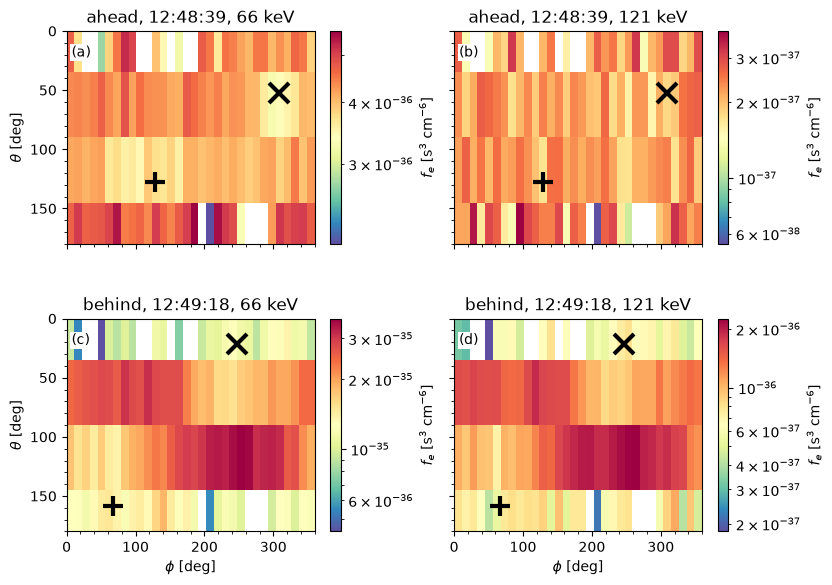

In [8]:
def plot_skymap(ax, vdf, i_t, i_e):
    # Bin edges from the angular widths of the skymap
    phi_c, theta_c = vdf.phi.data[i_t], vdf.theta.data
    phi = np.hstack([phi_c - vdf.attrs["delta_phi_minus"][i_t], 360.0])
    theta = np.hstack([theta_c - vdf.attrs["delta_theta_minus"], 180.0])
    data = vdf.data.data[i_t, i_e].T
    vmin = np.nanmin(data[data > 0]) if np.any(data > 0) else None
    mesh = ax.pcolormesh(phi, theta, data, norm=LogNorm(vmin=vmin), cmap="Spectral_r")
    ax.set_ylim([180, 0])
    return mesh


def look_direction(b_xyz):
    # Azimuth and polar angle of a direction (degrees)
    b_hat = b_xyz / np.linalg.norm(b_xyz)
    phi = np.rad2deg(np.arctan2(b_hat[1], b_hat[0])) % 360
    return phi, np.rad2deg(np.arccos(b_hat[2]))


# Last spin ending before the front and first spin starting after it
spin_end = np.append(vdf_e.time.data[1:], feeps_clean.time.data[-1])
spins = {
    "ahead": int(np.flatnonzero(spin_end <= t_df)[-1]),
    "behind": int(np.flatnonzero(vdf_e.time.data >= t_df)[0]),
}

f, axs = plt.subplots(2, 2, figsize=(9, 6.5), sharex="all", sharey="all")
f.subplots_adjust(hspace=0.35, wspace=0.25)
for row, (side, i_t) in zip(axs, spins.items()):
    t_spin = vdf_e.time.data[[i_t, i_t + 1]]
    b_spin = pyrf.time_clip(b_dmpa, t_spin).mean(dim="time").data
    for ax, i_e in zip(row, [1, 4]):
        mesh = plot_skymap(ax, vdf_e, i_t, i_e)
        f.colorbar(mesh, ax=ax, label="$f_e$ [s$^3$ cm$^{-6}$]")
        ax.plot(*look_direction(-b_spin), "k+", markersize=14, markeredgewidth=3)
        ax.plot(*look_direction(b_spin), "kx", markersize=14, markeredgewidth=3)
        energy = vdf_e.energy.data[i_t, i_e] / 1e3
        ax.set_title(f"{side}, {str(t_spin[0])[11:19]}, {energy:.0f} keV")
    row[0].set_ylabel("$\\theta$ [deg]")
for ax in axs[-1]:
    ax.set_xlabel("$\\phi$ [deg]")

label_options = dict(bbox=dict(facecolor="white", edgecolor="none", pad=1))
make_labels(axs.flatten(), [0.02, 0.88], **label_options)

## Coverage and partial moments
Bad eyes, the energy check and the sun masks leave bins without data, and the partial spins at both ends of the interval do not cover the sky. The `coverage` attribute is the fraction of the sphere with data at each time and energy. `psd_moments` counts the bins without data as zeros, so the moments are lower limits where the coverage is below 1; `fill_empty` fills them, here with the spin-averaged omni-directional flux (isotropic). The skymaps carry `angle_integration = "exact"`, so that `psd_moments` integrates the wide polar bins exactly, and `relativistic = True`, so that `psd_moments` uses the relativistic speeds: the density is the integral of the intensity $J / v$ over the energy and the solid angle (the non-relativistic moments of FPI and irfu-matlab underestimate it by about 10 % here). The moments are partial moments above 40 keV, coarse with 4 polar bins. The skymaps and spin averages are stamped at the start of each spin; the spectrograms show them at the centre of the spin.

In [9]:
vdf_e_fill = mms.feeps_skymap(feeps_clean, fill_empty="omni")

sc_pot = pyrf.ts_scalar(vdf_e.time.data, np.zeros(len(vdf_e.time)))
n_e = mms.psd_moments(vdf_e, sc_pot)[0]
n_e_fill = mms.psd_moments(vdf_e_fill, sc_pot)[0]

coverage = xr.DataArray(
    vdf_e.attrs["coverage"],
    coords=[vdf_e.time.data, vdf_e.energy.data[0] / 1e3],
    dims=["time", "energy"],
)
omni_e = mms.feeps_spin_avg(mms.feeps_omni(feeps_clean), feeps_clean.spinsectnum.data)


def spin_centres(inp):
    # Spin products are stamped at the start of each spin: plot them at the
    # centre of the spin
    start = inp.time.data
    end = np.append(start[1:], feeps_clean.time.data[-1])
    return inp.assign_coords(time=start + (end - start) / 2)

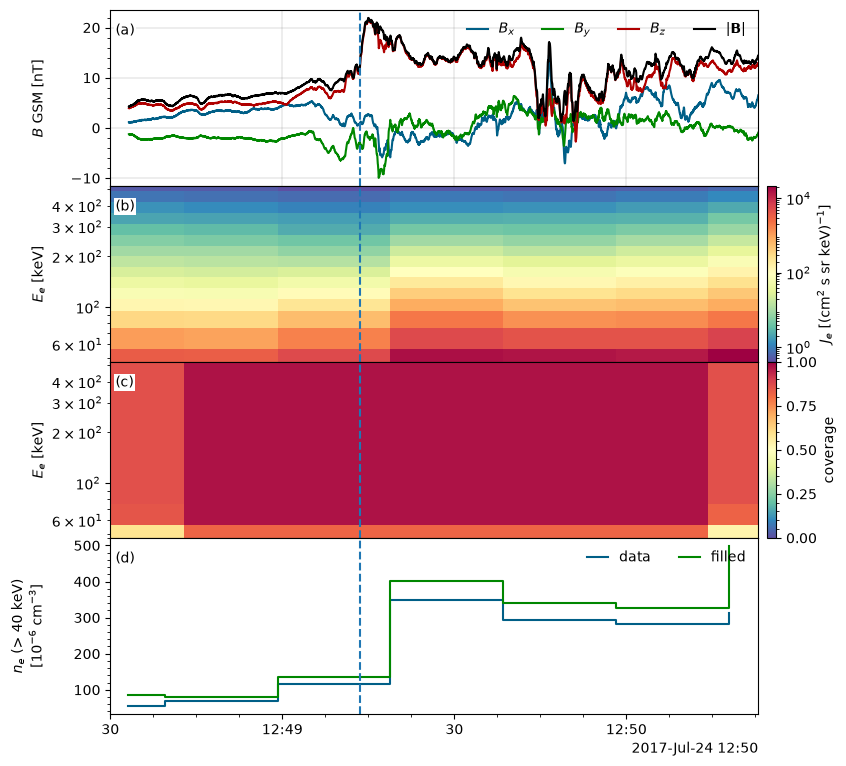

In [10]:
legend_options = dict(ncol=4, handlelength=1.5, loc="upper right", frameon=False)

f, axs = plt.subplots(4, sharex="all", figsize=(9, 8))
f.subplots_adjust(hspace=0, left=0.1, right=0.82, bottom=0.07, top=0.95)

plot_line(axs[0], b_gsm)
plot_line(axs[0], pyrf.norm(b_gsm), color="k")
axs[0].legend(["$B_x$", "$B_y$", "$B_z$", r"$|\mathbf{B}|$"], **legend_options)
axs[0].set_ylabel("$B$ GSM [nT]")

_, cax = plot_spectr(
    axs[1], spin_centres(omni_e), yscale="log", cscale="log", cmap="Spectral_r"
)
cax.set_ylabel("$J_e$ [(cm$^2$ s sr keV)$^{-1}$]")
axs[1].set_ylabel("$E_e$ [keV]")

_, cax = plot_spectr(
    axs[2], spin_centres(coverage), yscale="log", clim=[0, 1], cmap="Spectral_r"
)
cax.set_ylabel("coverage")
axs[2].set_ylabel("$E_e$ [keV]")

axs[3].step(n_e.time.data, 1e6 * n_e.data, where="post", label="data")
axs[3].step(n_e_fill.time.data, 1e6 * n_e_fill.data, where="post", label="filled")
axs[3].legend(**legend_options)
axs[3].set_ylabel("$n_e$ (> 40 keV)\n[$10^{-6}$ cm$^{-3}$]")

for ax in axs:
    ax.axvline(t_df, color="tab:blue", linestyle="--")

axs[-1].set_xlim(np.datetime64(tint[0]), np.datetime64(tint[1]))
label_options = dict(bbox=dict(facecolor="white", edgecolor="none", pad=1))
make_labels(axs, [0.008, 0.86], **label_options)
f.align_ylabels(axs)

## Pitch-angle and gyrophase distributions
The skymaps work with the FPI tools: pitch-angle and gyrophase distributions with the magnetic field in DMPA, averaged here over the channels between 40 and 100 keV, the gyrophase distribution for the electrons with pitch angles between 45 and 135 degrees. The gyrophase is measured right-handed about the magnetic field from the sunward direction (`r_xyz` = [1, 0, 0]); its resolution is limited by the 32 azimuths of the skymap.

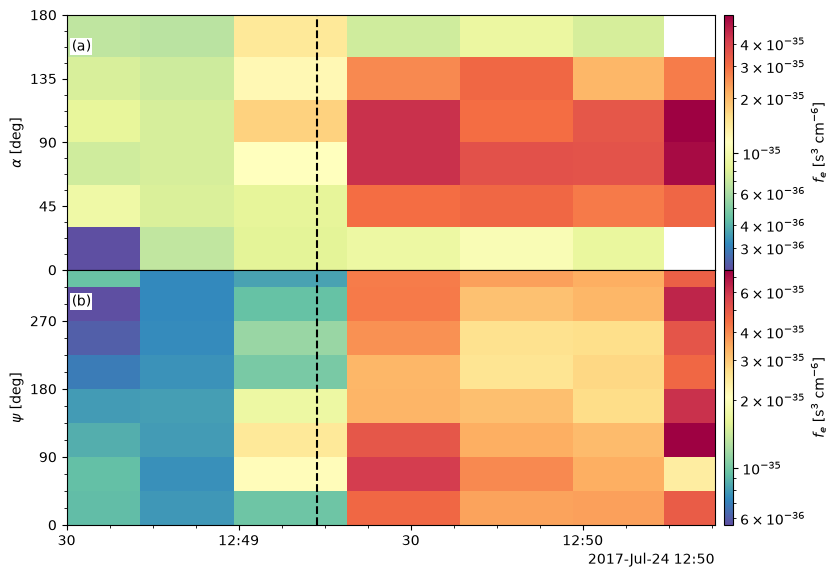

In [11]:
pad_e = mms.get_pitch_angle_dist(vdf_e, b_dmpa, angles=6, verbose=False)
gpd_e = mms.get_gyrophase_dist(vdf_e, b_dmpa, angles=8, pitch_angle_range=[45, 135])


def energy_average(dist, angle, e_min=40e3, e_max=100e3):
    # Mean over the energy channels in [e_min, e_max] (eV)
    in_range = (dist.energy.data[0] >= e_min) & (dist.energy.data[0] <= e_max)
    data = dist.data[:, in_range].mean(dim="idx0")
    return data.rename(idx1=angle).assign_coords({angle: dist[angle].data[0]})


f, axs = plt.subplots(2, sharex="all", figsize=(9, 6))
f.subplots_adjust(hspace=0, left=0.1, right=0.82, bottom=0.1, top=0.95)
for ax, dist, angle, label in [
    (axs[0], pad_e, "theta", "$\\alpha$"),
    (axs[1], gpd_e, "gyrophase", "$\\psi$"),
]:
    _, cax = plot_spectr(
        ax, spin_centres(energy_average(dist, angle)), cscale="log", cmap="Spectral_r"
    )
    cax.set_ylabel("$f_e$ [s$^3$ cm$^{-6}$]")
    ax.set_ylabel(f"{label} [deg]")
    ax.axvline(t_df, color="k", linestyle="--")
axs[0].set_yticks([0, 45, 90, 135, 180])
axs[1].set_yticks([0, 90, 180, 270])
axs[-1].set_xlim(np.datetime64(tint[0]), np.datetime64(tint[1]))
label_options = dict(bbox=dict(facecolor="white", edgecolor="none", pad=1))
make_labels(axs, [0.008, 0.86], **label_options)
f.align_ylabels(axs)

## Reduced distributions
`mms.reduce` integrates the skymaps over the directions perpendicular to a line (1D) or to a plane (2D), with Monte-Carlo particles drawn in each bin and relativistic speeds; the polar bins are the bands of the skymap (`delta_theta_minus/plus`). Their integral is the density of `psd_moments`. The frame has $x$ along the magnetic field averaged over each spin, $y = \hat{z} \times x$ and $z$ completing the triad (DMPA). FEEPS starts at about 40 keV ($1.1 \times 10^5$ km s$^{-1}$): the reduced distributions integrate a shell of speeds, so their low speeds come from the fast electrons moving across the line or the plane.

In [12]:
# Magnetic field averaged over each spin [start, next start)
b_spin = np.array(
    [
        b_dmpa.sel(time=slice(t_0, t_1)).mean(dim="time").data
        for t_0, t_1 in zip(vdf_e.time.data, spin_end)
    ]
)

x_hat = b_spin / np.linalg.norm(b_spin, axis=1, keepdims=True)
y_hat = np.cross([0.0, 0.0, 1.0], x_hat)
y_hat /= np.linalg.norm(y_hat, axis=1, keepdims=True)
z_hat = np.cross(x_hat, y_hat)
xyz = np.transpose(np.stack([x_hat, y_hat, z_hat]), [1, 2, 0])
xyz = pyrf.ts_tensor_xyz(vdf_e.time.data, xyz)

# Reduced distribution along the magnetic field, for all the spins
v_grid = np.linspace(-2.6e5, 2.6e5, 105)  # km/s
f_para = mms.reduce(vdf_e, xyz, "1d", "pol", vg=v_grid * 1e3, n_mc=500)

# Reduced distributions in the (v_par, v_perp) plane, ahead of and behind
# the front
f_2d = {}
for side, i_t in spins.items():
    t_spin = vdf_e.time.data[i_t] + np.array([0, 1], dtype="timedelta64[s]")
    tint_spin = list(pyrf.datetime642iso8601(t_spin))
    f_2d[side] = mms.reduce(
        vdf_e, xyz, "2d", "cart", vg=v_grid * 1e3, n_mc=500, tint=tint_spin
    )

100%|████████████████████████| 1/1 [00:00<00:00, 212.64it/s]


[<Axes: ylabel='$v_\\parallel$ [km s$^{-1}$]'>,
 <Axes: title={'center': 'ahead, 12:48:39'}, xlabel='$v_\\parallel$ [$10^3$ km s$^{-1}$]', ylabel='$v_\\perp$ [$10^3$ km s$^{-1}$]'>,
 <Axes: title={'center': 'behind, 12:49:18'}, xlabel='$v_\\parallel$ [$10^3$ km s$^{-1}$]', ylabel='$v_\\perp$ [$10^3$ km s$^{-1}$]'>]

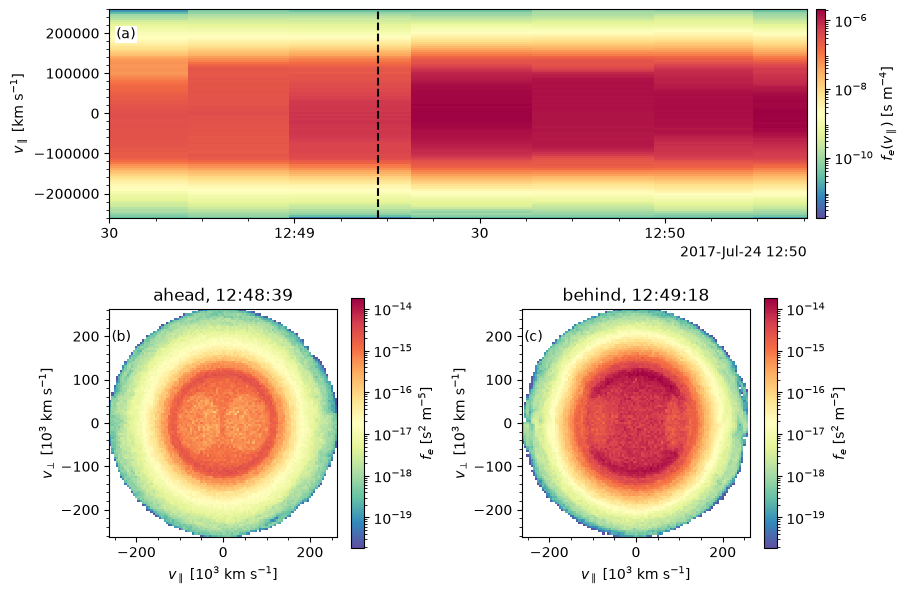

In [13]:
f = plt.figure(figsize=(9, 7))
gsp = f.add_gridspec(2, 2, height_ratios=[1, 1.2], hspace=0.35, wspace=0.45)

ax = f.add_subplot(gsp[0, :])
f_para_t = spin_centres(f_para.where(f_para > 0))
_, cax = plot_spectr(ax, f_para_t, cscale="log", cmap="Spectral_r")
cax.set_ylabel("$f_e(v_\\parallel)$ [s m$^{-4}$]")
ax.axvline(t_df, color="k", linestyle="--")
ax.set_ylabel("$v_\\parallel$ [km s$^{-1}$]")
ax.set_xlim(np.datetime64(tint[0]), np.datetime64(tint[1]))

f_max = max(np.nanmax(f_side.data) for f_side in f_2d.values())
for i, (side, f_side) in enumerate(f_2d.items()):
    ax = f.add_subplot(gsp[1, i])
    data = f_side.data[0].T
    mesh = ax.pcolormesh(
        f_side.vx.data / 1e3,
        f_side.vy.data / 1e3,
        np.where(data > 0, data, np.nan),
        norm=LogNorm(vmin=1e-6 * f_max, vmax=f_max),
        cmap="Spectral_r",
    )
    f.colorbar(mesh, ax=ax, label="$f_e$ [s$^2$ m$^{-5}$]")
    ax.set_aspect("equal")
    ax.set_xlabel("$v_\\parallel$ [$10^3$ km s$^{-1}$]")
    ax.set_ylabel("$v_\\perp$ [$10^3$ km s$^{-1}$]")
    ax.set_title(f"{side}, {str(f_side.time.data[0])[11:19]}")

label_options = dict(bbox=dict(facecolor="white", edgecolor="none", pad=1))
make_labels(f.axes[::2], [0.01, 0.86], **label_options)

Behind the front (dashed line), the energetic electron fluxes increase and the 40 to 100 keV electrons are enhanced perpendicular to the magnetic field, as in the pitch-angle distribution of Fig. 1h2 of Kolokotronis et al. (2026). The gyrophase distribution of the perpendicular electrons varies by less than a factor of 2 in the complete spins behind the front. With 4 polar bins and one skymap per spin, it is coarse, and the spin that contains the front mixes the magnetic field before and after it. The reduced distribution along the magnetic field increases behind the front by a factor of about 6 at small parallel speeds, against about 3 at the largest ones: the increase is largest for the electrons moving across the field.